# Frontier AI Topics in 2026: What Practitioners Are Talking About

> **Who is this for:** learners who know the basics of LLMs and want a clear, calm map of the "new" topics that AI engineers, researchers and educators keep posting about (on LinkedIn and elsewhere) in 2026.
>
> **What you will learn:**
> - a **map of 2026 topics** and where each one is taught in this repo
> - **reasoning models** and **test-time compute**, and how **RL with verifiable rewards (RLVR)** and **GRPO** train them (toy: best-of-N with a verifier, and a tiny GRPO loop)
> - **small language models**, **distillation** and **on-device / local AI** (toy: distil a big model into a small one)
> - **multimodal / omni models** and **voice agents** (pipeline vs native speech-to-speech, latency budget)
> - **Vision-Language-Action (VLA)** models, **embodied AI**, **world models** and the **JEPA** idea (toy: learn a world model, then plan with it)
> - **generative media**: diffusion transformers (DiT), **flow matching** (toy: turn noise into a 2-bump distribution), video generation
> - **mechanistic interpretability**: **sparse autoencoders**, circuit tracing, **steering vectors** (toys: sparse dictionary learning, a steering vector)
> - **AI safety and governance** updates (EU AI Act phases, frontier safety frameworks, dangerous-capability evals, content provenance / C2PA) (toy: a mini "content credential")
> - short tours of **agentic AI in production**, **AI for science**, **neuro-symbolic AI, KANs and hybrid architectures**, and **data** (synthetic data, curation, "data walls")
> - **how to keep up**: people and newsletters worth following, and how to check claims
>
> **Prerequisites:** [Start Here: How LLMs Work](00_start_here_how_llms_work.ipynb). Helpful: [Reasoning models](18_reasoning_models.ipynb), [Small language models](05_slms/01_small_language_models.ipynb), [Mechanistic interpretability](../19_AI_Ethics_and_Safety/08_mechanistic_interpretability.ipynb).
>
> **Time needed:** about 2 hours to read; the code runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. Only numpy, pandas, scikit-learn, matplotlib and the Python standard library. Every "model" here is a tiny toy or a scripted stand-in, and we say so each time.

**A note on dates.** This notebook was written in late 2026. Model names, product names and laws change quickly. Where something is fast-moving we say "as of late 2026" and keep the claim general. Always check the primary source (the paper, the official docs, the law text) before you rely on a detail.

## 0. Setup

We import a few libraries and fix the random seed. A **random seed** is a starting number for the random number generator, so you get the same "random" results every time you run the notebook.

In [1]:
import math, random, json, hashlib, hmac, re, time, warnings   # standard library helpers
from collections import Counter, deque

import numpy as np                     # arrays and maths
import pandas as pd                    # tables
import matplotlib.pyplot as plt        # plots

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.datasets import make_classification
from sklearn.decomposition import DictionaryLearning, PCA
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # keep toy output readable

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)      # numpy's modern random generator

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (6, 3.2)
print("Setup done. numpy", np.__version__)

Setup done. numpy 2.5.4


## 1. Map of 2026 topics

If you scroll through posts by AI practitioners in 2026, the same themes come up again and again. Some of them are big enough that this repo has a **dedicated notebook** for them. For those, here is a one-paragraph summary and a link. The rest of this notebook teaches the remaining topics.

| Topic | One-paragraph summary | Where it is taught |
|---|---|---|
| **Every RAG type and CAG** | RAG (retrieval-augmented generation) means "look things up, then answer". There are many flavours: naive, advanced, modular, graph RAG, agentic RAG, corrective RAG and more. CAG (cache-augmented generation) skips retrieval and pre-loads a small, fixed knowledge base into the model's context and cache. | [02_rag/05_every_rag_type_explained.ipynb](02_rag/05_every_rag_type_explained.ipynb) |
| **Caching and the KV cache** | LLMs save work by caching. The KV cache stores attention keys and values so earlier tokens are not recomputed. Prompt (prefix) caching reuses a shared start of a prompt across calls. Semantic caching reuses answers for questions that mean the same thing. | [23_llm_caching_kv_cache_prompt_semantic_cag.ipynb](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) |
| **How LLMs differ from each other** | Models differ in architecture (dense vs mixture-of-experts, attention variants such as MLA), training data, tokenizer, context length and post-training. Newer ideas include diffusion LLMs (generate text by refining many tokens at once), min-p sampling and model merging. | [24_how_llms_differ_from_each_other.ipynb](24_how_llms_differ_from_each_other.ipynb) |
| **LangChain** | A popular open-source framework for building LLM apps: prompts, models, tools, retrievers and chains share one interface, and LangGraph adds stateful agent graphs. | [25_langchain_complete_guide.ipynb](25_langchain_complete_guide.ipynb) |
| **Harness engineering, agentic engineering, spec-driven development, vibe coding** | The "harness" is everything around a model that makes an agent work: the loop, tools, prompts, checks and guardrails. Agentic engineering is building software *with* coding agents in a disciplined way. Spec-driven development writes the spec first and lets agents implement it. Vibe coding is the casual "just ask the AI and accept the code" style. | [../10_Agents/10_harness_engineering_and_agentic_engineering.ipynb](../10_Agents/10_harness_engineering_and_agentic_engineering.ipynb) |
| **Context engineering, agent memory, MCP and A2A** | Context engineering is choosing exactly what goes into the model's context window at each step. Agent memory keeps useful facts across steps and sessions. MCP (Model Context Protocol) is a standard way to connect tools and data to models; A2A (Agent2Agent) is a protocol for agents to talk to other agents. | [../10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb](../10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb) |
| **AI system design** | How to design a whole LLM product: requirements, model choice, retrieval, caching, guardrails, evals, cost and latency, and monitoring. | [../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) |
| **Quantum AI** | Quantum computing basics and quantum machine learning: qubits, circuits, variational models, and an honest view of what is and is not practical today. | [../25_Quantum_AI/](../25_Quantum_AI/) |

The remaining topics, taught below:

```mermaid
flowchart LR
    A[2026 frontier topics] --> B[2. Reasoning and RLVR]
    A --> C[3. Small models and on-device]
    A --> D[4. Multimodal and voice]
    A --> E[5. VLA, robots, world models]
    A --> F[6. Generative media]
    A --> G[7. Interpretability]
    A --> H[8. Safety and governance]
    A --> I[9-12. Agents, science, new architectures, data]
    A --> J[13. How to keep up]
```

## 2. Reasoning models, test-time compute, and RL with verifiable rewards

### 2.1 What it is

- A **reasoning model** is an LLM that is trained to "think out loud" (write a long chain of intermediate steps) before it gives the final answer.
- **Test-time compute** means the computing power spent *when the model is answering* (at "test time"), not when it is trained.
- **Test-time compute scaling** is the finding that you can often get better answers by letting the model spend more compute at answer time: think longer, try several answers, or check its own work.

**Simple analogy.** A student in an exam. Training is all the studying before the exam. Test-time compute is how long the student is allowed to think during the exam, and whether they can do a problem twice and compare. More thinking time helps, especially on hard problems.

### 2.2 Ways to spend test-time compute

| Method | What it does | Needs |
|---|---|---|
| Longer chain of thought | The model writes more reasoning steps before answering | A model trained to reason |
| Self-consistency (majority vote) | Sample several answers, pick the most common one | Nothing extra |
| Best-of-N with a verifier | Sample N answers, a checker picks one that passes | A verifier (program, tests, or reward model) |
| Search (tree search, beam search) | Explore many partial solutions, keep the promising ones | A way to score partial solutions |

A **verifier** is anything that can check whether an answer is right. For maths you can recompute the result. For code you can run the unit tests. This is why reasoning has improved fastest in maths and coding: answers there are **verifiable**.

### 2.3 Toy demo: best-of-N with a verifier

Below, a **fake solver** stands in for an LLM. It answers arithmetic questions correctly only some of the time (each problem gets its own made-up difficulty). The **verifier** recomputes the true answer, so it can tell a right answer from a wrong one. We measure accuracy as we allow more tries (N).

In [2]:
# --- toy problems: expressions like "7 + 3 * 5" ---------------------------
def make_problem(rng):
    a, b, c = rng.integers(2, 20, size=3)
    op1, op2 = rng.choice(["+", "-", "*"], size=2)
    return f"{a} {op1} {b} {op2} {c}"

problems = [make_problem(rng) for _ in range(300)]

# Each problem gets a made-up "chance the solver gets it right" (some easy, some hard).
p_correct = rng.uniform(0.05, 0.6, size=len(problems))

def fake_solver(expr, p, rng):
    # STAND-IN for an LLM: returns the right answer with probability p,
    # otherwise a plausible wrong answer (off by a small amount).
    truth = eval(expr)                  # safe here: we built the strings ourselves
    if rng.random() < p:
        return truth
    return truth + int(rng.choice([-3, -2, -1, 1, 2, 10]))

def verifier(expr, answer):
    # A *verifiable* check: recompute the answer exactly.
    return answer == eval(expr)

print("Example problem:", problems[0], "-> true answer", eval(problems[0]))
print("Five solver attempts:", [fake_solver(problems[0], p_correct[0], rng) for _ in range(5)])

Example problem: 3 - 15 - 13 -> true answer -25
Five solver attempts: [-27, -28, -25, -27, -23]


 N (tries)  best-of-N + verifier  majority vote
         1                 0.343          0.310
         2                 0.510          0.303
         4                 0.720          0.420
         8                 0.870          0.520
        16                 0.927          0.597
        32                 0.993          0.657


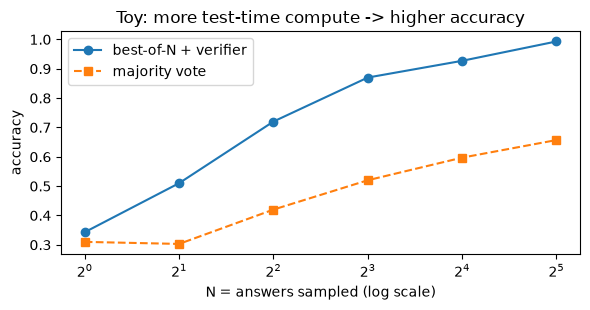

In [3]:
def best_of_n(expr, p, n, rng):
    # Try up to n answers; return the first one the verifier accepts (or the last try).
    ans = None
    for _ in range(n):
        ans = fake_solver(expr, p, rng)
        if verifier(expr, ans):
            return ans
    return ans

def majority_vote(expr, p, n, rng):
    # Self-consistency: no verifier, just pick the most common answer.
    answers = [fake_solver(expr, p, rng) for _ in range(n)]
    return Counter(answers).most_common(1)[0][0]

rows = []
for n in [1, 2, 4, 8, 16, 32]:
    acc_v = np.mean([verifier(e, best_of_n(e, p, n, rng)) for e, p in zip(problems, p_correct)])
    acc_m = np.mean([verifier(e, majority_vote(e, p, n, rng)) for e, p in zip(problems, p_correct)])
    rows.append({"N (tries)": n, "best-of-N + verifier": round(acc_v, 3), "majority vote": round(acc_m, 3)})

df_tt = pd.DataFrame(rows)
print(df_tt.to_string(index=False))

plt.plot(df_tt["N (tries)"], df_tt["best-of-N + verifier"], "o-", label="best-of-N + verifier")
plt.plot(df_tt["N (tries)"], df_tt["majority vote"], "s--", label="majority vote")
plt.xscale("log", base=2); plt.xlabel("N = answers sampled (log scale)"); plt.ylabel("accuracy")
plt.title("Toy: more test-time compute -> higher accuracy"); plt.legend(); plt.tight_layout(); plt.show()

**What just happened?**

- With one try, accuracy is just the solver's average skill.
- With a **verifier**, accuracy climbs quickly as N grows, because we only need *one* correct try out of N. If a single try is right with probability p, the chance that at least one of N tries is right is 1 - (1 - p)^N.
- **Majority vote** helps less here, because the wrong answers are spread around and the right one is not always the most common. Majority vote works best when the model is right more often than it is wrong in any single direction.
- The cost: N times more compute. Gains also flatten out: going from 16 to 32 tries adds little.

The repo's [Reasoning models notebook](18_reasoning_models.ipynb) goes deeper into chain of thought, process reward models and tree search.

### 2.4 How reasoning models are trained: RL with verifiable rewards (RLVR)

**What it is.** **Reinforcement learning (RL)** trains a model by trial and error: it tries something, gets a **reward** (a score), and is nudged towards actions that scored well. **RLVR** (reinforcement learning with verifiable rewards) uses a reward that a program can check, for example "is the final maths answer correct?" or "do the unit tests pass?", instead of a reward model trained on human preferences.

**Analogy.** Practice problems with an answer key at the back of the book. You do not need a teacher to grade each attempt; the answer key tells you right or wrong.

**GRPO** (Group Relative Policy Optimization, introduced in the DeepSeekMath paper and used for DeepSeek-R1) is a popular RL algorithm for this:

1. For one question, sample a **group** of G answers from the model.
2. Score each answer with the verifiable reward (for example 1 = correct, 0 = wrong).
3. Compute each answer's **advantage** = (its reward - group average) / group standard deviation. "Advantage" means "how much better than the group's typical answer".
4. Make the model more likely to produce answers with positive advantage, and less likely for negative ones.

The trick is step 3: the group itself is the baseline, so GRPO does not need a separate "value" network (which the older PPO method uses). That saves memory and makes it simpler.

### 2.5 Toy demo: a tiny GRPO loop

Our "policy" (the model) chooses one of four **strategies** for solving a problem. Each strategy has a hidden success rate. The policy starts with no preference. GRPO-style updates with a 0/1 verifiable reward should teach it to prefer the best strategy.

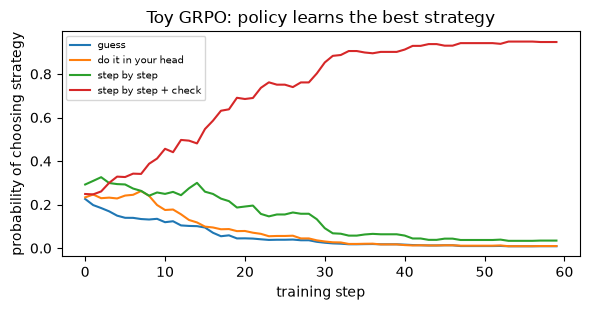

Final probabilities: {'guess': 0.009, 'do it in your head': 0.01, 'step by step': 0.035, 'step by step + check': 0.947}


In [4]:
strategies   = ["guess", "do it in your head", "step by step", "step by step + check"]
success_rate = np.array([0.10, 0.35, 0.60, 0.80])   # hidden from the policy (made-up numbers)

logits = np.zeros(4)            # the policy's parameters: start with equal preference
G, lr = 8, 0.5                  # group size and learning rate

def softmax(z):
    z = z - z.max()
    return np.exp(z) / np.exp(z).sum()

history = []
for step in range(60):
    probs = softmax(logits)
    actions = rng.choice(4, size=G, p=probs)                       # 1. sample a group
    rewards = (rng.random(G) < success_rate[actions]).astype(float) # 2. verifiable 0/1 reward
    adv = (rewards - rewards.mean()) / (rewards.std() + 1e-6)       # 3. group-relative advantage
    grad = np.zeros(4)
    for a, A in zip(actions, adv):                                  # 4. policy-gradient step
        one_hot = np.eye(4)[a]
        grad += A * (one_hot - probs)    # gradient of log softmax(a) times advantage
    logits += lr * grad / G
    history.append(softmax(logits))

history = np.array(history)
for i, s in enumerate(strategies):
    plt.plot(history[:, i], label=s)
plt.xlabel("training step"); plt.ylabel("probability of choosing strategy")
plt.title("Toy GRPO: policy learns the best strategy"); plt.legend(fontsize=7); plt.tight_layout(); plt.show()
print("Final probabilities:", {s: round(float(p), 3) for s, p in zip(strategies, history[-1])})

**What just happened?** Nobody told the policy which strategy was best. It only saw "right" or "wrong" for each try, compared each try to the rest of its group, and shifted probability towards strategies that did better than the group average. Real RLVR does the same with an LLM, where an "action" is a whole written solution.

**When to use reasoning models / when not to**

| Use them when | Avoid them when |
|---|---|
| Multi-step maths, code, planning, tricky analysis | Simple lookups, chit-chat, classification |
| Wrong answers are costly and you can wait | You need very low latency or very low cost |
| You can verify answers (tests, checkers) | There is no way to check, and long reasoning just adds cost |

**Where it is going (as of late 2026).** RLVR is being extended beyond maths and code to tasks with partly checkable outcomes (agent tasks in sandboxes, tool use, rubric-graded writing). Practitioners also talk about "reasoning budgets" (letting the user or app choose how long the model thinks) and about the risk of **reward hacking**: the model finds a way to get the reward without really solving the task, for example by editing the tests instead of fixing the code.

**How to try it.** Open-source RL libraries (for example Hugging Face TRL, which includes a GRPO trainer) let you run GRPO on a small open model with a GPU. Shown as code only, since it needs a GPU and a model download:

```python
# needs: pip install trl transformers datasets  (and a GPU)
from trl import GRPOConfig, GRPOTrainer

def correct_answer_reward(completions, answer, **kwargs):
    # verifiable reward: 1.0 if the final answer matches, else 0.0
    return [1.0 if c.strip().endswith(str(a)) else 0.0 for c, a in zip(completions, answer)]

trainer = GRPOTrainer(model="<small-open-model>", reward_funcs=correct_answer_reward,
                      args=GRPOConfig(output_dir="grpo-demo"), train_dataset=my_math_dataset)
trainer.train()
```

## 3. Small language models, distillation, and on-device AI

### 3.1 What it is

- A **small language model (SLM)** is an LLM with relatively few parameters (roughly under ~10 billion as a loose rule of thumb), small enough to run on a laptop, a phone, or a cheap server.
- **On-device AI** means the model runs on the user's own device instead of in the cloud.
- **Distillation** means training a small "student" model to copy the behaviour of a large "teacher" model.

**Analogy.** A master chef (teacher) writes down exactly how they cook a few hundred dishes. An apprentice (student) learns by copying those examples. The apprentice will not know everything the chef knows, but for the dishes on the menu they can get surprisingly close, and they are much cheaper to hire.

### 3.2 Why it matters now

| Reason | Explanation |
|---|---|
| Cost | Many app tasks (classify, extract, route, summarise) do not need a frontier model |
| Latency | No network round trip; responses start faster |
| Privacy | Data can stay on the device |
| Offline | Works without internet |
| Agents | Agents make many small calls; a small model for the easy steps saves a lot of money |

### 3.3 How distillation works

```mermaid
flowchart LR
    D[Prompts / unlabeled inputs] --> T[Big teacher model]
    T -->|answers or probabilities| S[Small student model]
    D --> S
    S --> E[Evaluate on held-out data]
```

The student can learn from the teacher's final answers ("hard labels") or from the teacher's full probability distribution ("soft labels"). Soft labels carry more information: "70% cat, 25% fox" tells you more than just "cat". This is the idea in Hinton et al.'s 2015 paper "Distilling the Knowledge in a Neural Network". For LLMs, a very common practical form is: have a strong model write many good answers, then fine-tune a small model on them.

### 3.4 Toy demo: distil a big forest into a small tree

Stand-ins: the **teacher** is a 300-tree random forest. The **student** is a single shallow decision tree. We have only 300 human-labelled examples but 4,000 unlabelled ones. The teacher labels the unlabelled pool, and the student learns from the teacher's soft probabilities.

In [5]:
X, y = make_classification(n_samples=6000, n_features=20, n_informative=8,
                           n_redundant=4, class_sep=0.8, random_state=SEED)
X_lab, y_lab = X[:300], y[:300]          # small human-labelled set
X_pool        = X[300:4300]              # unlabelled inputs (no y used!)
X_test, y_test = X[4300:], y[4300:]      # held-out test set

# Teacher: big model trained on the labelled data plus... we pretend it was trained
# on lots of other data, so we give it more labels than the student gets.
teacher = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
teacher.fit(X[:2000], y[:2000])

# Student A: small tree, trained only on the 300 human labels
student_a = DecisionTreeClassifier(max_depth=6, random_state=SEED).fit(X_lab, y_lab)

# Student B: small tree, trained to copy the teacher's SOFT probabilities on the big pool
soft = teacher.predict_proba(X_pool)[:, 1]                       # teacher's P(class 1)
student_b = DecisionTreeRegressor(max_depth=6, random_state=SEED).fit(X_pool, soft)

def n_nodes_forest(rf): return sum(t.tree_.node_count for t in rf.estimators_)
res = pd.DataFrame([
    {"model": "teacher (300-tree forest)", "accuracy": (teacher.predict(X_test) == y_test).mean(),
     "size (tree nodes)": n_nodes_forest(teacher)},
    {"model": "student A (tree, 300 human labels)", "accuracy": (student_a.predict(X_test) == y_test).mean(),
     "size (tree nodes)": student_a.tree_.node_count},
    {"model": "student B (tree, distilled from teacher)", "accuracy": ((student_b.predict(X_test) > 0.5) == y_test).mean(),
     "size (tree nodes)": student_b.tree_.node_count},
])
res["accuracy"] = res["accuracy"].round(3)
print(res.to_string(index=False))

                                   model  accuracy  size (tree nodes)
               teacher (300-tree forest)     0.885             135684
      student A (tree, 300 human labels)     0.708                 43
student B (tree, distilled from teacher)     0.805                117


**What just happened?** The distilled student is far smaller than the teacher (about a thousand times fewer nodes) and usually beats the student that only saw the small labelled set, because the teacher gave it thousands of extra (soft) examples to learn from. It still does not fully match the teacher. That is the usual trade: a little quality for a lot of speed and cost.

### 3.5 Local runtimes (how people run SLMs on their own machine)

These tools are described here, not run, because they need a separate install and a model download.

| Runtime | What it is | Typical use |
|---|---|---|
| **llama.cpp** | A C/C++ inference engine for running LLMs on CPUs and GPUs, using the **GGUF** file format and quantized weights | The engine under many local tools; very portable |
| **Ollama** | A friendly app and command-line tool that downloads and runs open models locally and exposes a local HTTP API | Quick local experiments, local RAG apps |
| **MLX** | Apple's array framework for machine learning on Apple silicon (M-series chips); `mlx-lm` runs and fine-tunes LLMs | Local models on Macs |
| Others | LM Studio (desktop app), ONNX Runtime, vendor on-device SDKs for phones | Desktop and mobile apps |

**Quantization** (storing weights with fewer bits, for example 4-bit instead of 16-bit) is what makes most of this fit in memory. See [Inference optimization](13_inference_optimization.ipynb).

```bash
# Ollama example (needs Ollama installed and a model downloaded; not run here)
ollama pull <small-model-name>
ollama run  <small-model-name> "Summarise this paragraph in one sentence: ..."
```

**When to use / when not to.** Use SLMs for narrow, well-defined tasks, privacy-sensitive data and high-volume calls. Avoid them for open-ended expert reasoning or broad world knowledge, unless you add retrieval or route hard cases to a bigger model ("model routing").

**Where it is going (as of late 2026).** More capable small models, better on-device chips (NPUs, neural processing units), and hybrid apps that run a small model locally and call a cloud model only when needed. More detail: [Small language models](05_slms/01_small_language_models.ipynb).

## 4. Multimodal and omni models, and voice agents

### 4.1 What it is

- A **multimodal model** understands (and sometimes produces) more than one kind of data: text, images, audio, video.
- An **omni model** is a multimodal model built to take in and produce *several* modalities in one model, often including real-time speech.
- A **voice agent** is an AI system you talk to by voice that can also take actions (book, look up, transfer a call).

**Analogy.** A traditional voice assistant is like a relay team: one runner turns speech into text, another thinks, another speaks. An omni model is one runner who does all three legs.

### 4.2 Two ways to build a voice agent

```mermaid
flowchart LR
    subgraph Pipeline["Cascaded pipeline"]
        M1[Mic audio] --> VAD1[Voice activity detection] --> ASR[Speech-to-text] --> LLM[Text LLM + tools] --> TTS[Text-to-speech] --> S1[Speaker]
    end
    subgraph Native["Native speech-to-speech"]
        M2[Mic audio] --> VAD2[Voice activity detection] --> OMNI[One audio-in, audio-out model + tools] --> S2[Speaker]
    end
```

| | Cascaded pipeline (ASR -> LLM -> TTS) | Native speech-to-speech |
|---|---|---|
| How | Three separate models chained together | One model hears audio and speaks audio |
| Latency | Higher (each stage adds delay), but streaming helps a lot | Lower, more natural turn-taking |
| Tone and emotion | Mostly lost when speech becomes text | Can hear and express tone, laughter, hesitation |
| Control and debugging | Easy: you can read the transcript, swap any part | Harder: less visible in the middle |
| Choice of LLM | Any text LLM, including your own fine-tuned one | Limited to models that support audio |
| Typical fit (as of late 2026) | Call centres needing strict control and logs | Conversational assistants where naturalness matters |

Key terms: **ASR** (automatic speech recognition) turns speech into text. **TTS** (text-to-speech) turns text into speech. **VAD** (voice activity detection) decides when someone is speaking. **Endpointing** decides when the user has *finished* their turn. **Barge-in** means the user can interrupt the agent mid-sentence.

### 4.3 The latency budget

People notice delay in conversation quickly. Studies of turn-taking across many languages find that the usual gap between speakers is short, on the order of a couple of hundred milliseconds (Stivers et al., 2009). Voice agents usually cannot get that low, but every stage counts. A **latency budget** is a table that splits the allowed total delay across the stages. The numbers below are **illustrative only**, not measurements.

In [6]:
# Illustrative latency budgets (milliseconds until the user hears the first sound).
# These are made-up but plausible-looking numbers for teaching, NOT benchmarks.
pipeline = {
    "endpointing (wait to be sure user stopped)": 300,
    "speech-to-text (final transcript)":          150,
    "LLM time-to-first-token":                     350,
    "text-to-speech time-to-first-audio":          150,
    "network round trips":                         100,
}
native = {
    "endpointing (wait to be sure user stopped)": 300,
    "speech-to-speech model first audio":          300,
    "network round trips":                         100,
}
for name, budget in [("Cascaded pipeline", pipeline), ("Native speech-to-speech", native)]:
    print(f"\n{name}")
    for stage, ms in budget.items():
        print(f"  {stage:<45} {ms:>5} ms")
    print(f"  {'TOTAL':<45} {sum(budget.values()):>5} ms")

print("\nTip: streaming (start TTS on the first LLM words) overlaps stages, "
      "so the real total is often lower than the sum.")


Cascaded pipeline
  endpointing (wait to be sure user stopped)      300 ms
  speech-to-text (final transcript)               150 ms
  LLM time-to-first-token                         350 ms
  text-to-speech time-to-first-audio              150 ms
  network round trips                             100 ms
  TOTAL                                          1050 ms

Native speech-to-speech
  endpointing (wait to be sure user stopped)      300 ms
  speech-to-speech model first audio              300 ms
  network round trips                             100 ms
  TOTAL                                           700 ms

Tip: streaming (start TTS on the first LLM words) overlaps stages, so the real total is often lower than the sum.


**What just happened?** Adding up the stages shows where the time goes. Endpointing and the LLM's first token are often the biggest parts, so that is where teams optimise first: smarter end-of-turn detection, smaller or faster models for the first reply, and streaming every stage.

**How to try it.** Open-source frameworks for real-time voice agents exist (for example Pipecat and LiveKit Agents), and several model providers offer real-time speech APIs. They need audio devices and API keys, so they are not run here. The [Multimodal AI](11_multimodal/01_multimodal_ai.ipynb) and [Vision-language models](06_vision_llm/01_vision_language_models.ipynb) notebooks cover the model side.

**Where it is going (as of late 2026).** Better full-duplex models (listening and speaking at the same time, like a phone call), voice agents in customer service and healthcare intake, and more attention to safety issues such as voice cloning and consent.

## 5. Vision-Language-Action models, embodied AI, and world models

### 5.1 Vision-Language-Action (VLA) models

**What it is.** A **VLA model** takes in camera images and a text instruction ("put the red cup in the sink") and outputs **actions** for a robot (arm movements, gripper open/close). It is a vision-language model whose output is robot actions instead of (or as well as) text. **Embodied AI** is the broader field of AI that acts in the physical world through a body (a robot, a car, a drone).

**Analogy.** A chatbot is a brain in a jar that can only talk. A VLA gives that brain eyes and hands.

**How it works (simplified).**
1. Start from a vision-language model pre-trained on internet images and text (so it already knows what a "cup" is).
2. Add a way to output actions: either as special "action tokens" or through a separate small "action head" (some recent designs use flow matching or diffusion to produce smooth action sequences; see section 6).
3. Fine-tune on many recorded robot demonstrations (camera frames + the actions a human operator took).

Well-known examples in the literature include Google DeepMind's RT-2, the open-source OpenVLA, and Physical Intelligence's pi0. As of late 2026 several labs and companies also talk about **robotics foundation models**: one large model trained on data from many robot types that can be adapted to new robots and tasks.

| Why it matters now | Main open problems |
|---|---|
| Internet knowledge helps robots handle new objects and instructions | Robot data is scarce and expensive to collect |
| One model for many tasks, instead of one program per task | Safety: mistakes in the physical world can hurt people |
| Humanoid and warehouse robots are a big investment area | Reliability is still far below what most factories need |

### 5.2 World models

**What it is.** A **world model** is a model that predicts *what will happen next* in an environment if you take a certain action. Once you have one, you can **plan**: imagine several action sequences inside the model, and pick the one that leads to the best outcome, before doing anything in the real world.

**Analogy.** Before you move a chess piece, you picture the board after the move. That mental picture is your world model.

Two flavours people talk about:
- **World models for planning** in RL and robotics (for example the "World Models" paper by Ha and Schmidhuber, and the Dreamer family): a learned simulator inside the agent's head.
- **Video world models**: large models that generate video of a world that reacts to your actions (for example Google DeepMind's Genie line). They can act as training grounds for agents and robots.

### 5.3 The JEPA idea

**What it is.** **JEPA** (Joint-Embedding Predictive Architecture) is an idea promoted by Yann LeCun: instead of predicting every pixel of the future (very hard, and mostly irrelevant detail like leaves moving), **predict the future in an embedding space**. An **embedding** is a compact list of numbers that summarises the important content of an input. I-JEPA (images) and V-JEPA (video) are published examples from Meta.

**Analogy.** If you throw a ball, you predict *where it will land*, not the exact pattern of light on every blade of grass. JEPA tries to learn that kind of "important-parts-only" prediction.

| | Generative (pixel) prediction | JEPA (embedding) prediction |
|---|---|---|
| Predicts | Every pixel / token of the future | A compact summary of the future |
| Cost | High | Lower |
| Risk | Wastes effort on unpredictable details | Must avoid "collapse" (all embeddings becoming the same) |

See also [Self-supervised learning](../05_Deep_Learning/09_self_supervised_learning.ipynb), which covers JEPA-style training in more depth.

### 5.4 Toy demo: learn a world model, then plan with it

A 7 x 7 gridworld. The agent starts on the left and must reach a goal on the right. Hidden twist: in the middle columns there is **wind** that pushes the agent up by one row on every move (like the classic "windy gridworld"). The agent does not know this.

1. The agent is dropped on random squares, tries random actions, and records (state, action, next state).
2. It fits a **linear regression** world model: predict the change in position from the action and the current column.
3. It **plans** by searching over actions *inside the learned model* (breadth-first search), then executes the plan in the real world.

We compare with a naive plan that ignores the wind. Note our model predicts a compact state (x, y), not pixels, which is the JEPA spirit in miniature.

In [7]:
W, H = 7, 7
START, GOAL = (0, 3), (6, 3)
WIND = {2: 1, 3: 1, 4: 1}              # column -> upward push (hidden from the agent)
ACTIONS = {0: (0, 1), 1: (0, -1), 2: (-1, 0), 3: (1, 0)}    # up, down, left, right
ANAMES = {0: "up", 1: "down", 2: "left", 3: "right"}

def clip(x, y): return (min(max(x, 0), W - 1), min(max(y, 0), H - 1))

def true_step(state, a):
    # The REAL environment (the agent cannot see this code).
    x, y = state
    dx, dy = ACTIONS[a]
    return clip(x + dx, y + dy + WIND.get(x, 0))

# 1. Collect random experience: drop the agent at random squares, try a random action
data = []
for _ in range(600):
    s = (int(rng.integers(W)), int(rng.integers(H)))
    a = int(rng.integers(4))
    data.append((s, a, true_step(s, a)))

# 2. Fit a linear world model: features = one-hot(action) + one-hot(column) -> (dx, dy)
def features(state, a):
    f = np.zeros(4 + W)
    f[a] = 1.0
    f[4 + state[0]] = 1.0
    return f

Xw = np.array([features(s, a) for s, a, _ in data])
Yw = np.array([(s2[0] - s[0], s2[1] - s[1]) for s, _, s2 in data])
world_model = LinearRegression().fit(Xw, Yw)

def model_step(state, a):
    dx, dy = world_model.predict(features(state, a)[None, :])[0]
    return clip(state[0] + int(round(dx)), state[1] + int(round(dy)))

print("Learned effect of 'right' in column 0 (no wind):", model_step((0, 3), 3))
print("Learned effect of 'right' in column 3 (windy):  ", model_step((3, 3), 3))

Learned effect of 'right' in column 0 (no wind): (1, 3)
Learned effect of 'right' in column 3 (windy):   (4, 4)


In [8]:
def plan_bfs(step_fn, start, goal, max_len=20):
    # Breadth-first search over action sequences, using step_fn as the "imagination".
    frontier, seen = deque([(start, [])]), {start}
    while frontier:
        state, plan = frontier.popleft()
        if state == goal: return plan
        if len(plan) >= max_len: continue
        for a in ACTIONS:
            nxt = step_fn(state, a)
            if nxt not in seen:
                seen.add(nxt); frontier.append((nxt, plan + [a]))
    return None

def naive_step(state, a):          # a "world model" that ignores the wind
    dx, dy = ACTIONS[a]
    return clip(state[0] + dx, state[1] + dy)

def execute(plan):
    s, path = START, [START]
    for a in plan:
        s = true_step(s, a); path.append(s)
    return s, path

for name, fn in [("naive (no wind)", naive_step), ("learned world model", model_step)]:
    plan = plan_bfs(fn, START, GOAL)
    end, path = execute(plan)
    print(f"{name:<20} plan = {[ANAMES[a] for a in plan]}")
    print(f"{'':<20} ends at {end}  -> {'REACHED GOAL' if end == GOAL else 'missed the goal'}\n")

naive (no wind)      plan = ['right', 'right', 'right', 'right', 'right', 'right']
                     ends at (6, 6)  -> missed the goal

learned world model  plan = ['down', 'down', 'down', 'right', 'right', 'right', 'right', 'right', 'right']
                     ends at (6, 3)  -> REACHED GOAL



**What just happened?** The naive plan walks straight right and the wind blows it off course. The learned world model discovered the wind from experience, so its plan steps down before (or while) crossing the windy columns and lands on the goal. That is the core promise of world models: **learn how the world reacts, then think before acting**.

Real systems replace our linear regression with large neural networks, our 2-number state with learned embeddings of camera images, and our breadth-first search with methods like model-predictive control (re-plan after every step) or RL inside the imagined world. See also [Advanced RL](../11_Reinforcement_Learning/06_advanced_rl.ipynb) for model-based RL.

**Where it is going (as of late 2026).** World models are one of the most-discussed research directions, partly because some well-known researchers argue that next-token prediction alone is not enough for physical understanding. Expect more video world models used as simulators for training robots and agents, and more robot foundation models trained on mixed data (real robots, simulation, human videos).

## 6. Generative media: diffusion transformers, flow matching, video generation

### 6.1 Quick refresher: diffusion

A **diffusion model** learns to turn random noise into data (an image, audio, video) step by step. During training, we add noise to real images and teach the network to undo it. At generation time we start from pure noise and repeatedly "denoise". The [Image generation](../06_Computer_Vision/06_image_generation.ipynb) and [Generative models hands-on](../05_Deep_Learning/20_generative_models_hands_on.ipynb) notebooks cover this in detail.

### 6.2 Diffusion Transformers (DiT)

**What it is.** A **DiT** is a diffusion model whose denoising network is a **transformer** (the same architecture as LLMs) instead of the older U-Net (a convolutional network). The image (or its compressed "latent" version) is cut into **patches**, and each patch becomes a token.

**Analogy.** Instead of a specialised photo-editing tool, you use the same general-purpose "reader of token sequences" that powers LLMs, and treat image patches as words.

**Why it matters now.** Transformers scale well: bigger models and more data reliably give better results. Many recent image and video generators are described by their makers as transformer-based diffusion or flow models (the original DiT paper is Peebles and Xie, 2022). For video, the patches become **spacetime patches** (small cubes across several frames).

### 6.3 Flow matching

**What it is.** **Flow matching** is a newer, simpler way to train generative models. Instead of learning to remove noise in many small random steps, the model learns a **velocity field**: at every point and time, "which direction and how fast should I move" to travel from noise to data. **Rectified flow** is a closely related method that uses straight-line paths.

**Analogy.** Imagine each noise sample is a passenger and each real data point is a destination. Flow matching trains a "traffic controller" that, for any passenger at any moment, says which way to walk. If the routes are straight lines, you can get there in very few steps.

**How it works (straight-line version).**
1. Take a noise sample x0 (from a bell curve) and a real data sample x1.
2. Pick a random time t between 0 and 1. The point on the straight line is x_t = (1 - t) * x0 + t * x1.
3. The velocity along that line is simply x1 - x0.
4. Train a regressor: input (x_t, t), target (x1 - x0).
5. To generate: start from fresh noise and follow the learned velocity in small steps from t = 0 to t = 1 (this is **Euler integration**: new position = old position + velocity * step size).

### 6.4 Toy demo: 1-D flow matching

Target distribution: two bumps (at -2 and +2). Source: one bell curve centred at 0. A small gradient-boosting regressor from scikit-learn plays the role of the neural network.

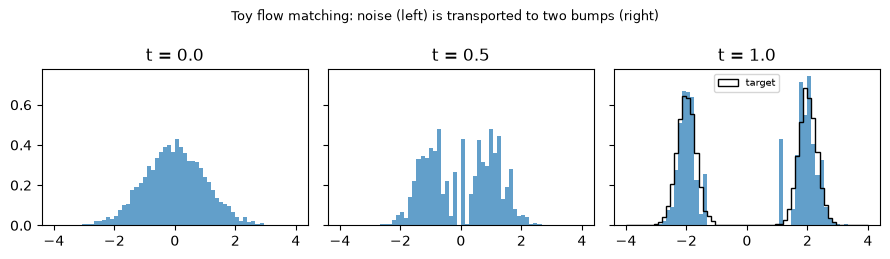

Fraction of generated samples near a bump (|x| between 1 and 3): 0.997
Fraction near 0 (|x| < 0.7), which should be small: 0.0


In [9]:
n = 20000
x0 = rng.normal(0, 1, n)                                   # noise samples
x1 = rng.choice([-2.0, 2.0], n) + rng.normal(0, 0.3, n)    # target: two bumps
t  = rng.uniform(0, 1, n)                                  # random times
xt = (1 - t) * x0 + t * x1                                 # point on the straight line
v_target = x1 - x0                                         # velocity along the line

velocity_model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED)
velocity_model.fit(np.column_stack([xt, t]), v_target)     # learn v(x, t)

# Generate: start from fresh noise, follow the learned velocity with Euler steps
steps = 40
x = rng.normal(0, 1, 5000)
snapshots = {0.0: x.copy()}
for k in range(steps):
    tk = k / steps
    v = velocity_model.predict(np.column_stack([x, np.full_like(x, tk)]))
    x = x + v * (1 / steps)
    if k + 1 in (steps // 2, steps):
        snapshots[round((k + 1) / steps, 2)] = x.copy()

fig, axes = plt.subplots(1, 3, figsize=(9, 2.6), sharey=True)
for ax, (tt, xs) in zip(axes, snapshots.items()):
    ax.hist(xs, bins=60, range=(-4, 4), density=True, color="tab:blue", alpha=0.7)
    ax.set_title(f"t = {tt}")
axes[2].hist(x1[:5000], bins=60, range=(-4, 4), density=True, histtype="step", color="k", label="target")
axes[2].legend(fontsize=7)
plt.suptitle("Toy flow matching: noise (left) is transported to two bumps (right)", fontsize=9)
plt.tight_layout(); plt.show()

print("Fraction of generated samples near a bump (|x| between 1 and 3):",
      round(np.mean((np.abs(x) > 1) & (np.abs(x) < 3)), 3))
print("Fraction near 0 (|x| < 0.7), which should be small:", round(np.mean(np.abs(x) < 0.7), 3))

**What just happened?** We never told the model "make two bumps". It only learned "which way to move" from pairs of noise and data points. Following that velocity field carried a single bell curve of noise into two separate bumps. Real image models do the same thing in a space with millions of dimensions, with a large transformer (a DiT) as the velocity model.

**When to use which (rough guide)**

| Approach | Strength | Weakness |
|---|---|---|
| GANs (older) | Very fast generation | Unstable training, less variety |
| Diffusion | High quality, stable training | Many steps at generation time (slower) |
| Flow matching / rectified flow | Simple training objective, straighter paths, often fewer steps | Still an active research area |

### 6.5 Video generation

**What it is.** Video models generate short clips from text or images. Most are diffusion or flow models with a transformer backbone working on spacetime patches of a compressed video.

**Why it matters now (as of late 2026).** Quality and clip length have improved a lot, several models also generate matching audio, and they are used in advertising, film previsualisation and social media. The same technology feeds into **video world models** (section 5).

**Main issues.** High compute cost, keeping objects and physics consistent over time, copyright questions about training data, and **deepfakes** (realistic fake videos of real people). This is why content provenance (section 8) matters. See [Deepfake detection](../19_AI_Ethics_and_Safety/07_deepfake_detection.ipynb) and [Copyright and AI](../19_AI_Ethics_and_Safety/06_copyright_and_ai.ipynb).

## 7. Mechanistic interpretability: SAEs, circuit tracing, steering vectors

**Mechanistic interpretability** is the study of *how* a neural network computes its answers, by looking at its internal numbers (activations and weights) and finding human-understandable parts. An **activation** is the list of numbers a layer produces for an input. The repo's [Mechanistic interpretability notebook](../19_AI_Ethics_and_Safety/08_mechanistic_interpretability.ipynb) covers the basics (probing, superposition). Here we focus on three tools practitioners talk about a lot.

### 7.1 Sparse autoencoders (SAEs)

**The problem: superposition.** A model has more **concepts** ("features") to represent than it has neurons, so it packs many features into the same neurons, like overlapping radio signals. One neuron then responds to several unrelated things. This is called **superposition**.

**What an SAE is.** A **sparse autoencoder** is a small extra network trained on a model's activations. It re-expresses each activation as a combination of a **larger** set of directions (a "dictionary"), with the rule that only a **few** directions may be active at once (that is what **sparse** means). Each dictionary direction often turns out to match one clean concept.

**Analogy.** A smoothie tastes like a blur. An SAE is like a tool that tells you "this one is mostly banana, a bit of strawberry, a pinch of ginger", using a long list of possible ingredients but only a few per smoothie.

### 7.2 Toy demo: recover hidden features with sparse dictionary learning

We create 12 hidden "concept" directions squeezed into only 6 dimensions (superposition). Each fake activation is made of 1-3 active concepts. Then we ask:
- **PCA** (principal component analysis, which finds at most 6 directions here) and
- **sparse dictionary learning** (scikit-learn's `DictionaryLearning`, the classic method behind SAEs, with 12 atoms)

to find the hidden directions. We score how well each true concept is matched (cosine similarity, 1.0 = perfect match).

In [10]:
d, n_feat, n_samples = 6, 12, 1500
true_dirs = rng.normal(size=(n_feat, d))
true_dirs /= np.linalg.norm(true_dirs, axis=1, keepdims=True)     # 12 unit vectors in 6-D

# Sparse codes: each sample uses a few concepts with positive strengths
codes = np.zeros((n_samples, n_feat))
for i in range(n_samples):
    k = rng.integers(1, 4)                                       # 1 to 3 active concepts
    idx = rng.choice(n_feat, size=k, replace=False)
    codes[i, idx] = rng.uniform(0.5, 1.5, size=k)
acts = codes @ true_dirs + rng.normal(0, 0.02, size=(n_samples, d))   # "model activations"

def match_score(found_dirs):
    found = found_dirs / np.linalg.norm(found_dirs, axis=1, keepdims=True)
    cos = np.abs(true_dirs @ found.T)          # |cosine| between every true and found direction
    return cos.max(axis=1)                     # best match for each true concept

pca = PCA(n_components=d).fit(acts)
dl = DictionaryLearning(n_components=n_feat, alpha=0.05, max_iter=300, fit_algorithm="cd",
                        transform_algorithm="lasso_cd", positive_code=True, random_state=SEED)
dl.fit(acts)

for name, dirs in [("PCA (6 directions)", pca.components_), ("Sparse dictionary (12 atoms)", dl.components_)]:
    s = match_score(dirs)
    print(f"{name:<30} mean match = {s.mean():.3f}   concepts matched with cos > 0.9: {(s > 0.9).sum()}/{n_feat}")

PCA (6 directions)             mean match = 0.740   concepts matched with cos > 0.9: 3/12
Sparse dictionary (12 atoms)   mean match = 0.994   concepts matched with cos > 0.9: 12/12


**What just happened?** PCA can only find as many directions as there are dimensions (6), and they are mixtures, so it matches only a few of the 12 overlapping concepts well. Sparse dictionary learning uses more directions than dimensions *plus* a sparsity rule, so it recovers most of the hidden concepts cleanly. Real SAEs do the same on LLM activations with thousands to millions of dictionary features, trained as a neural network. Published work (for example Anthropic's "Towards Monosemanticity" and "Scaling Monosemanticity") found features for concepts such as specific cities, code bugs or emotional tone.

### 7.3 Circuit tracing and attribution graphs (conceptual)

**What it is.** A **circuit** is a small group of features and connections inside a model that together perform one step of computation (for example "find the capital of the country mentioned"). **Circuit tracing** tries to map these. An **attribution graph** is a diagram showing which internal features contributed to a specific output, and how strongly.

**Analogy.** Tracing which pipes in a building carried the water to one particular tap.

```mermaid
flowchart LR
    T1["token: 'Dallas'"] --> F1[feature: Texas]
    F1 --> F2[feature: say a capital]
    T2["token: 'capital of the state'"] --> F2
    F2 --> O["output: 'Austin'"]
```

How it works (simplified): replace hard-to-read parts of the model with interpretable stand-ins (for example "transcoders", which are SAE-like layers), then measure how much each feature's activation pushes on later features and on the final output. Anthropic's 2025 "Circuit Tracing" and "On the Biology of a Large Language Model" papers popularised this, and open tools to build such graphs on open models have followed. Limits: the stand-ins do not explain everything, and each graph explains one prompt, not the whole model.

### 7.4 Steering vectors

**What it is.** A **steering vector** is a direction in activation space that you **add** to a model's activations while it runs, to push its behaviour (for example more formal, more positive, or less likely to refuse). It is often computed as the **difference of means**: average activation on examples *with* a property minus the average *without* it. Related terms: **activation steering**, **activation addition**, **representation engineering**.

**Analogy.** Turning a single "mood" knob on a mixing desk instead of re-recording the whole song.

### 7.5 Toy demo: compute and apply a steering vector

Stand-in: 16-number "activations" for formal and casual sentences, where formality is hidden along one direction. A logistic-regression **probe** (a simple classifier reading the activations) tells us how "formal" an activation looks. We steer casual activations and watch the probe's view change.

In [11]:
dim = 16
formal_dir = rng.normal(size=dim); formal_dir /= np.linalg.norm(formal_dir)
base = rng.normal(size=(400, dim))                         # unrelated "content" variation
formal_acts = base[:200] + 1.5 * formal_dir                # formal sentences
casual_acts = base[200:] - 1.5 * formal_dir                # casual sentences

probe = LogisticRegression(max_iter=1000).fit(
    np.vstack([formal_acts, casual_acts]), np.r_[np.ones(200), np.zeros(200)])

steer = formal_acts.mean(axis=0) - casual_acts.mean(axis=0)     # difference of means
print("cosine(steering vector, hidden formality direction) =",
      round(float(steer @ formal_dir / np.linalg.norm(steer)), 3))

for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
    steered = casual_acts + alpha * steer                  # add the vector while "running"
    print(f"alpha = {alpha:<4}  average P(formal) from probe = {probe.predict_proba(steered)[:, 1].mean():.2f}")

cosine(steering vector, hidden formality direction) = 0.992
alpha = 0.0   average P(formal) from probe = 0.09
alpha = 0.25  average P(formal) from probe = 0.27
alpha = 0.5   average P(formal) from probe = 0.54
alpha = 0.75  average P(formal) from probe = 0.78
alpha = 1.0   average P(formal) from probe = 0.92


**What just happened?** The difference of means pointed almost exactly along the hidden "formality" direction. Adding more of it moved casual activations towards "formal". In a real LLM you would add the vector to the residual stream at one layer during generation and see the text style change. Too much steering usually breaks fluency, so the strength is tuned.

| Tool | Question it answers | Typical use (as of late 2026) |
|---|---|---|
| Probes | "Is concept X readable from this layer?" | Quick checks, monitoring |
| SAEs | "What features does the model use?" | Feature discovery, auditing |
| Circuit tracing | "How did it produce *this* answer?" | Debugging specific behaviours |
| Steering vectors | "Can I change behaviour without retraining?" | Research, light-touch behaviour control |

**Where it is going.** Interpretability is increasingly used in safety work (looking for features related to deception or harmful knowledge, auditing models before release). It is still an active research field: methods are imperfect and partial, so treat claims like "we fully understand model X" with care.

## 8. AI safety and governance updates (as of late 2026)

This section is kept general and factual. Laws and frameworks change, so check the official source before relying on any date. The repo's [AI regulation and compliance](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb) and [Responsible AI](../19_AI_Ethics_and_Safety/04_responsible_ai.ipynb) notebooks go deeper.

### 8.1 EU AI Act: obligations arrive in phases

The **EU AI Act** (Regulation (EU) 2024/1689) is the European Union's law on AI. It sorts AI uses by **risk level**: banned practices, high-risk systems (for example in hiring, credit, medical devices), systems with transparency duties (for example chatbots and AI-generated content), and minimal-risk systems. It also has rules for **general-purpose AI (GPAI) models**, meaning foundation models such as large LLMs.

| Date (as originally written in the Act) | What starts to apply |
|---|---|
| 1 August 2024 | The Act enters into force |
| 2 February 2025 | Bans on "unacceptable-risk" practices; AI literacy duties |
| 2 August 2025 | Obligations for providers of general-purpose AI models; governance bodies |
| 2 August 2026 | Most remaining rules, including many high-risk obligations and transparency duties |
| 2 August 2027 | High-risk rules for AI built into products covered by other EU safety laws |

**Important update.** In 2025-2026 the EU worked on a "Digital Omnibus" simplification package that **postpones some high-risk deadlines** (reported new dates are in late 2027 and 2028). Check the official EU sources (EUR-Lex, the Commission's AI Act pages) for the final, current dates before planning compliance work.

A **code of practice** for general-purpose AI model providers was published by the European Commission in 2025 as a voluntary way to show compliance.

### 8.2 Frontier safety frameworks

A **frontier safety framework** is a public policy from an AI developer that says: "we will test our most capable models for certain dangerous capabilities, and if a model crosses a threshold, we will apply stronger safeguards (or not release it)". Examples include Anthropic's Responsible Scaling Policy, OpenAI's Preparedness Framework and Google DeepMind's Frontier Safety Framework. Several AI companies signed the voluntary Frontier AI Safety Commitments at the AI Seoul Summit (May 2024), which included publishing such frameworks. Some governments have also started to require transparency about such frameworks for the largest developers (for example California's SB 53, signed in 2025).

### 8.3 Evals for dangerous capabilities

**Dangerous-capability evaluations** are tests that measure whether a model could meaningfully help with seriously harmful activities. Commonly discussed areas:

| Area | What is tested (in general terms) |
|---|---|
| CBRN | Whether the model gives real uplift towards chemical, biological, radiological or nuclear harm |
| Cyber | Whether it can find or exploit software vulnerabilities on its own |
| Autonomy / self-replication | Whether it can acquire resources or act for long periods without oversight |
| AI R&D | Whether it can substantially speed up AI research itself |
| Persuasion / deception | Whether it can manipulate people or hide its intentions from evaluators |

Government bodies such as the UK AI Security Institute and the US Center for AI Standards and Innovation (CAISI) run or support such testing. Results are often published in a model's **system card** (a document describing a model, its tests and its safeguards).

### 8.4 Watermarking and content provenance (C2PA)

- **Watermarking** hides a signal inside AI-generated content (an image, audio, or even text) so a detector can later say "this was AI-generated". Google DeepMind's **SynthID** is one example. Watermarks can sometimes be weakened by editing.
- **Content provenance** attaches a signed record to a file saying who made it, with what tool, and what edits were made. **C2PA** (Coalition for Content Provenance and Authenticity) is an open technical standard for this; the user-facing name is **Content Credentials**.

**Analogy.** A watermark is like invisible ink inside the paper. A C2PA manifest is like a signed, tamper-evident receipt stapled to the document.

### 8.5 Toy demo: a mini "content credential"

Real C2PA uses public-key certificates and a standard file format. Our stand-in uses a shared secret key and an HMAC (a keyed hash) just to show the core idea: **hash the content, sign the claim, and any change breaks the check**.

In [12]:
SECRET_KEY = b"demo-signing-key"     # stand-in for a real private key / certificate

def make_credential(content: bytes, tool: str):
    manifest = {
        "claim_generator": tool,
        "assertions": ["created with a generative AI tool"],
        "content_sha256": hashlib.sha256(content).hexdigest(),   # fingerprint of the content
    }
    payload = json.dumps(manifest, sort_keys=True).encode()
    signature = hmac.new(SECRET_KEY, payload, hashlib.sha256).hexdigest()
    return {"manifest": manifest, "signature": signature}

def verify(content: bytes, cred):
    payload = json.dumps(cred["manifest"], sort_keys=True).encode()
    sig_ok  = hmac.compare_digest(hmac.new(SECRET_KEY, payload, hashlib.sha256).hexdigest(), cred["signature"])
    hash_ok = hashlib.sha256(content).hexdigest() == cred["manifest"]["content_sha256"]
    return {"signature valid": sig_ok, "content unchanged": hash_ok}

image_bytes = b"\x89PNG...pretend these are the pixels of an AI-generated image..."
cred = make_credential(image_bytes, tool="toy-image-generator v1")
print("Manifest:", json.dumps(cred["manifest"], indent=2))
print("Original file :", verify(image_bytes, cred))
print("Edited file   :", verify(image_bytes + b" one pixel changed", cred))

forged = json.loads(json.dumps(cred)); forged["manifest"]["claim_generator"] = "a real camera"
print("Forged claim  :", verify(image_bytes, forged))

Manifest: {
  "claim_generator": "toy-image-generator v1",
  "assertions": [
    "created with a generative AI tool"
  ],
  "content_sha256": "88462e9c2acbd6cf6c9775f50b52b25509ebfe6181dbaa518fc9688fefae0dfb"
}
Original file : {'signature valid': True, 'content unchanged': True}
Edited file   : {'signature valid': True, 'content unchanged': False}
Forged claim  : {'signature valid': False, 'content unchanged': True}


**What just happened?** The credential binds a claim ("made by an AI tool") to an exact fingerprint of the file. Editing the file breaks the fingerprint, and editing the claim breaks the signature. Real C2PA also records allowed edits as a chain of signed steps. Its main weakness: provenance can be **stripped** (for example by taking a screenshot), so it proves where something came from when present, but its absence proves nothing.

**Where it is going (as of late 2026).** More cameras, editing tools and platforms support Content Credentials; laws such as the EU AI Act's transparency rules push for labelling AI-generated content; and safety frameworks and third-party evaluations are becoming a normal part of releasing frontier models.

## 9. Agentic AI in production: the 2026 trends (short tour)

An **agent** is an LLM in a loop that can use tools, observe the results and decide the next step. The [10_Agents](../10_Agents/) folder teaches agents in depth; this is just a map of what practitioners discuss.

| Trend | What it is | Watch-outs | Learn more |
|---|---|---|---|
| **Computer-use / browser agents** | Agents that see a screen (screenshots or page structure) and click, type and scroll like a person | Slow, can be tricked by malicious web pages (prompt injection), need careful permissions | [Advanced agent frameworks](../10_Agents/07_advanced_agent_frameworks.ipynb), [Agent security](../10_Agents/08_agent_security.ipynb) |
| **CLI coding agents** | Agents that work in your terminal and code repository: read files, run tests, edit code, open pull requests | Need tests and review; can make large confident mistakes | [Harness engineering](../10_Agents/10_harness_engineering_and_agentic_engineering.ipynb) |
| **Vertical agents** | Agents built for one industry or job (legal review, customer support, accounting, healthcare admin) | Domain evals, compliance, human hand-off | [Industry tool-using agent](../10_Agents/09_industry_tool_using_agent.ipynb) |
| **Agent payments and commerce (emerging)** | Protocols that let agents buy things on a user's behalf with proof the user approved, for example Google's Agent Payments Protocol (AP2) and the Agentic Commerce Protocol from OpenAI and Stripe (both announced in 2025) | Very early; fraud, consent and liability rules are still forming | Official protocol docs |
| **Multi-agent systems** | Several specialised agents that cooperate (planner, researcher, coder, reviewer) | More cost and more failure points; often a single agent with good tools is enough | [Multi-agent frameworks](../10_Agents/04_multi_agent_frameworks.ipynb) |
| **Agent observability and evals** | Tracing every step, measuring task success, catching regressions | Without this, agents are hard to trust | [Agent observability](../10_Agents/06_agent_observability.ipynb) |

A widely shared security idea from Simon Willison is the **"lethal trifecta"**: an agent that has (1) access to private data, (2) exposure to untrusted content, and (3) a way to send data out, can be tricked by prompt injection into leaking that data. Avoid giving one agent all three. See [LLM security](16_llm_security.ipynb).

## 10. AI for science (short tour)

**What it is.** Using machine learning to speed up scientific discovery: predicting structures, simulating physics, and proposing new candidates for experiments.

| Area | What AI does | Well-known examples |
|---|---|---|
| **Protein structure** | Predicts a protein's 3-D shape from its amino-acid sequence | AlphaFold 2 and AlphaFold 3 (Google DeepMind and Isomorphic Labs); RoseTTAFold. The 2024 Nobel Prize in Chemistry went to David Baker (protein design) and Demis Hassabis and John Jumper (protein structure prediction) |
| **Protein design** | Generates new proteins with a desired shape or function, often with diffusion models | RFdiffusion (Baker lab) |
| **Materials** | Predicts which new crystal structures are stable, to find candidate materials | GNoME (Google DeepMind) and others; candidates still need lab confirmation |
| **Weather** | Learned weather models that forecast faster than traditional physics simulations, trained on decades of past weather data | GraphCast and GenCast (Google DeepMind); ECMWF's AIFS |
| **Maths and algorithms** | LLM-guided search that proposes and checks new solutions or proofs | Systems that pair an LLM with an automatic checker (again: verifiable rewards) |

**Why it matters now.** Some of these models are already in practical use (protein structure prediction in labs, AI weather forecasts alongside traditional ones). "AI scientist" agents that read papers, plan experiments and analyse results are a frequent 2026 talking point; treat strong claims carefully and look for independent validation.

**Learn more in this repo:** [Bioinformatics sequence ML](../03_Machine_Learning/18_domain_applications/02_bioinformatics_sequence_ml.ipynb), [Geospatial ML](../03_Machine_Learning/18_domain_applications/01_geospatial_machine_learning.ipynb), [Graph ML hands-on](../05_Deep_Learning/21_graph_machine_learning_hands_on.ipynb).

## 11. Neuro-symbolic AI, KANs, and hybrid architectures (short tour)

### 11.1 Neuro-symbolic AI

**What it is.** Combining **neural networks** (good at patterns, language, perception) with **symbolic** systems (explicit rules, logic, search, code, maths solvers that are exact).

**Analogy.** A creative person with a calculator: intuition proposes, the calculator checks.

**Where you already see it (as of late 2026).** LLMs that write and run code, LLMs that call a solver or a theorem prover, knowledge graphs plus LLMs, and the verifier in section 2. See [Knowledge representation and logic](../00_AI_Fundamentals/classical_ai/07_knowledge_representation_and_logic.ipynb) and [Knowledge graphs](09_knowledge_graphs/).

### 11.2 Kolmogorov-Arnold Networks (KANs)

**What it is.** A **KAN** is a neural network where the learnable parts are **small 1-D functions on the edges** (for example splines, which are smooth curves made of pieces), instead of single weights with a fixed activation function on the nodes as in a normal MLP. It is inspired by the Kolmogorov-Arnold representation theorem (Liu et al., 2024).

| | MLP | KAN |
|---|---|---|
| Learnable part | Weights (numbers) on edges | Functions (curves) on edges |
| Activation | Fixed (for example ReLU) on nodes | Learned per edge |
| Claimed strengths | Mature, fast on GPUs | Can be more interpretable on small scientific problems |
| Status (as of late 2026) | The default everywhere | Research interest; not a replacement for transformers in LLMs |

See [Neural ODEs](../05_Deep_Learning/10_neural_ode.ipynb), which also discusses KANs.

### 11.3 Hybrid attention and state-space architectures

**What it is.** **Attention** (the core of transformers) compares every token with every earlier token, so its memory (the KV cache) grows with the length of the text. A **state-space model (SSM)** such as **Mamba** keeps a **fixed-size** running summary instead, like a notebook that never gets more pages. **Hybrid** models mix a few attention layers with many SSM or linear-attention layers to get most of the quality of attention with much less memory on long inputs. Examples in the literature include Jamba (AI21) and several 2025 open models that interleave attention with linear-attention or SSM layers.

A quick back-of-the-envelope calculation (the configuration is **illustrative**, not a real model):

In [13]:
# Illustrative config: 32 layers, 8 KV heads x 128 dims, 16-bit numbers (2 bytes)
layers, kv_heads, head_dim, bytes_per = 32, 8, 128, 2
ssm_state_per_layer = 4096 * 16 * bytes_per          # fixed-size state (illustrative)

def kv_bytes_per_layer(tokens):                      # keys + values for every token
    return 2 * kv_heads * head_dim * tokens * bytes_per

rows = []
for tokens in [8_000, 128_000, 1_000_000]:
    full   = layers * kv_bytes_per_layer(tokens)
    ssm    = layers * ssm_state_per_layer
    hybrid = 8 * kv_bytes_per_layer(tokens) + 24 * ssm_state_per_layer   # 1 in 4 layers is attention
    rows.append({"context tokens": f"{tokens:,}", "all-attention (GB)": round(full / 1e9, 2),
                 "hybrid 1:3 (GB)": round(hybrid / 1e9, 2), "all-SSM (GB)": round(ssm / 1e9, 3)})
print(pd.DataFrame(rows).to_string(index=False))

context tokens  all-attention (GB)  hybrid 1:3 (GB)  all-SSM (GB)
         8,000                1.05             0.27         0.004
       128,000               16.78             4.20         0.004
     1,000,000              131.07            32.77         0.004


**What just happened?** All-attention memory grows in a straight line with context length. All-SSM memory stays flat. The hybrid sits in between, which is why hybrids are attractive for long-context and agent workloads. The catch: pure SSMs can be worse at exact recall ("find that one sentence 100,000 tokens ago"), which is what the remaining attention layers are for. More in [LLM architecture innovations](14_llm_architecture_innovations.ipynb) and [How LLMs differ](24_how_llms_differ_from_each_other.ipynb).

## 12. Data: synthetic data, curation, and "data walls"

### 12.1 What it is

- **Synthetic data** is training data generated by a program or by another model, instead of collected from people.
- **Data curation** is choosing *which* data to train on: removing duplicates, junk and harmful content, and balancing topics. Many teams say curation matters as much as model size.
- The **"data wall"** is the worry that models will run out of new high-quality human-written text to train on. Researchers at Epoch AI estimated that the stock of public human text could be fully used for training at some point in the coming years (Villalobos et al., "Will we run out of data?"); exact timing is uncertain and debated.

**Analogy.** A student who has read every textbook in the library. To keep improving they either write their own practice problems (synthetic data), re-read only the best books more carefully (curation), or learn by doing (RL and interaction, section 2).

### 12.2 Toy demo: curation (deduplicate and filter)

A tiny pipeline: normalise text, remove duplicates (by hashing the normalised text, so case and punctuation do not matter), remove **near-duplicates** (by comparing overlapping 3-word "shingles" with Jaccard similarity), and drop low-quality documents with simple rules. Real pipelines use the same ideas at a huge scale (for example MinHash to find near-duplicates quickly, and model-based quality classifiers).

In [14]:
docs = [
    "The mitochondria is the powerhouse of the cell and produces energy for the cell.",
    "The mitochondria is the powerhouse of the cell and produces energy for the cell.",   # exact dup
    "the Mitochondria is the powerhouse of the cell, and produces energy for the cell!",   # same after normalising
    "Photosynthesis lets plants turn sunlight, water and carbon dioxide into sugar.",
    "BUY NOW!!! $$$ CLICK HERE $$$ BEST DEALS!!! $$$",                                     # junk
    "ok",                                                                                   # too short
    "Gradient descent updates parameters a small step in the direction that lowers the loss.",
    "Gradient descent updates the parameters a small step in the direction that lowers the loss.",  # near dup
    "home | about | contact | home | about | contact | home | about | contact",            # boilerplate
]

def normalise(t): return re.sub(r"[^a-z0-9 ]", "", t.lower()).split()
def shingles(t, k=3):
    w = normalise(t); return {" ".join(w[i:i + k]) for i in range(max(1, len(w) - k + 1))}
def jaccard(a, b): return len(a & b) / max(1, len(a | b))

def quality_problem(t):
    words = t.split()
    if len(words) < 5: return "too short"
    if sum(not c.isalnum() and not c.isspace() for c in t) / len(t) > 0.15: return "too many symbols"
    if len(set(words)) / len(words) < 0.5: return "too repetitive"
    return None

kept, log, seen_hashes = [], [], set()
for t in docs:
    h = hashlib.md5(" ".join(normalise(t)).encode()).hexdigest()
    reason = quality_problem(t)
    if reason is None and h in seen_hashes: reason = "duplicate (after normalising)"
    if reason is None and any(jaccard(shingles(t), shingles(k)) > 0.5 for k in kept): reason = "near duplicate"
    if reason is None:
        kept.append(t); seen_hashes.add(h)
    log.append({"decision": "KEEP" if reason is None else "drop", "reason": reason or "", "text": t[:70]})
print(pd.DataFrame(log).to_string(index=False))

decision                        reason                                                                   text
    KEEP                               The mitochondria is the powerhouse of the cell and produces energy for
    drop duplicate (after normalising) The mitochondria is the powerhouse of the cell and produces energy for
    drop duplicate (after normalising) the Mitochondria is the powerhouse of the cell, and produces energy fo
    KEEP                               Photosynthesis lets plants turn sunlight, water and carbon dioxide int
    drop              too many symbols                        BUY NOW!!! $$$ CLICK HERE $$$ BEST DEALS!!! $$$
    drop                     too short                                                                     ok
    KEEP                               Gradient descent updates parameters a small step in the direction that
    drop                near duplicate Gradient descent updates the parameters a small step in the direction 
    drop  

### 12.3 Toy demo: synthetic data with a verifier

The safest synthetic data is data you can **check**. Here a fake "generator model" (a stand-in for an LLM) writes question-answer pairs, sometimes with wrong answers. A verifier keeps only correct pairs. This "generate, then filter" pattern is how a lot of maths and code training data is made, and it connects back to RLVR in section 2.

In [15]:
def fake_generator(rng):
    # STAND-IN for an LLM writing a practice problem and its answer (wrong 30% of the time).
    a, b = rng.integers(10, 99, size=2)
    answer = a * b if rng.random() > 0.3 else a * b + int(rng.choice([-10, -1, 1, 10]))
    return {"question": f"What is {a} x {b}?", "answer": int(answer), "a": int(a), "b": int(b)}

raw = [fake_generator(rng) for _ in range(1000)]
clean = [r for r in raw if r["a"] * r["b"] == r["answer"]]     # verifier: recompute exactly
print(f"generated {len(raw)} pairs, kept {len(clean)} verified pairs ({len(clean)/len(raw):.0%})")
print("example kept pair:", {k: clean[0][k] for k in ("question", "answer")})

generated 1000 pairs, kept 694 verified pairs (69%)
example kept pair: {'question': 'What is 39 x 67?', 'answer': 2613}


**When synthetic data helps / when it hurts**

| Helps | Hurts |
|---|---|
| You can verify it (maths, code, structured extraction) | It is unchecked and repeats the generator's mistakes |
| You need rare cases, edge cases, or privacy-safe examples | It lacks diversity, so the model learns a narrow "style" |
| Distilling a big model into a small one (section 3) | Training repeatedly on a model's own unfiltered output can degrade quality over generations (often called "model collapse") |

**Where it is going (as of late 2026).** Most frontier training pipelines are described as using a large share of synthetic and heavily filtered data, especially for post-training; RL environments ("gyms" where agents practise tasks with checkable outcomes) are increasingly treated as a kind of data. More in [Synthetic data](10_synthetic_data/01_synthetic_data.ipynb).

## 13. How to keep up

### 13.1 People who post regularly about these topics

These are well-known educators and practitioners who share their work publicly on LinkedIn and/or other places (blogs, X, newsletters, GitHub, YouTube). Focus areas are described generally and can change over time. No ranking is implied.

| Person | Generally known for / posts about |
|---|---|
| Andrew Ng | AI education (DeepLearning.AI, The Batch newsletter), agentic AI workflows |
| Andrej Karpathy | Building LLMs from scratch (educational code and videos), how LLMs work, coined "vibe coding", agentic engineering |
| Sebastian Raschka | LLM architectures, building LLMs from scratch, research paper summaries (Ahead of AI) |
| Chip Huyen | AI engineering and ML systems in production (author of *Designing Machine Learning Systems* and *AI Engineering*) |
| Eugene Yan | Applied ML and LLM systems, evals, recommendation systems |
| Hamel Husain | LLM evals, error analysis, looking at your data |
| Simon Willison | Practical LLM tools, prompt injection, the "lethal trifecta", detailed blog notes on new models |
| Aurimas Griciūnas | AI engineering, LLMOps, agent architectures (SwirlAI newsletter) |
| Paul Iusztin | AI engineering, end-to-end LLM systems (Decoding ML; co-author of the *LLM Engineer's Handbook*) |
| Damien Benveniste | ML and LLM engineering explained (The AiEdge newsletter) |
| Elvis Saravia | LLM research summaries, prompt and context engineering (DAIR.AI, Prompt Engineering Guide) |
| Shubham Saboo | AI agents and open-source agent app examples (awesome-llm-apps repository) |
| Aishwarya Srinivasan | AI careers, AI education, agentic AI skills |
| Maxime Labonne | LLM fine-tuning and model merging, the open "LLM Course" (co-author of the *LLM Engineer's Handbook*) |
| Philipp Schmid | Open models, fine-tuning and agents, hands-on technical guides |
| Jerry Liu | RAG and document agents (LlamaIndex) |
| Harrison Chase | LangChain and LangGraph, agent harnesses and agent design |
| Ethan Mollick | AI at work and in education, how organisations adopt AI (One Useful Thing) |
| Yann LeCun | World models, JEPA, self-supervised learning, open research |

### 13.2 Newsletters, podcasts and primary sources

| Source | What it is |
|---|---|
| The Batch | Weekly AI news and commentary from DeepLearning.AI |
| Import AI | Jack Clark's newsletter on AI research and policy |
| Latent Space | Newsletter and podcast for AI engineers |
| Ahead of AI | Sebastian Raschka's newsletter on LLM research |
| Interconnects | Nathan Lambert's newsletter on post-training, RL and open models |
| Simon Willison's Weblog | Frequent, hands-on notes on LLM tools and releases |
| One Useful Thing | Ethan Mollick's newsletter on AI at work and in education |
| Primary sources | arXiv papers, official lab blogs and model/system cards, official docs, law texts (EUR-Lex) |

### 13.3 How to read posts critically

- **Go to the primary source.** If a post says "new paper shows X", open the paper and read the abstract, the setup and the limitations.
- **Many LinkedIn posts are promotional.** Posts often sell a course, a product, a newsletter or a personal brand. That does not make them wrong, but it changes the incentives.
- **Watch for missing details:** what dataset, what baseline, what model size, who ran the test, and can it be reproduced?
- **Benchmarks are not your use case.** Run a small eval on your own data before switching models ([LLM evaluation hands-on](22_llm_evaluation_hands_on.ipynb)).
- **New names for old ideas are common.** Many "new" terms are rebrandings or small variations. Ask "what is actually different?"
- **Prefer people who show their work:** code, data, failed experiments and clear limitations.

## 14. 2026 topics checklist

Use this as a study checklist. Each row points to where the topic is taught in this repo.

| Topic | Where it is taught in this repo |
|---|---|
| Every RAG type, CAG | [02_rag/05_every_rag_type_explained.ipynb](02_rag/05_every_rag_type_explained.ipynb) |
| KV cache, prompt caching, semantic caching | [23_llm_caching_kv_cache_prompt_semantic_cag.ipynb](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) |
| How LLMs differ (MoE, MLA, diffusion LLMs, min-p, model merging) | [24_how_llms_differ_from_each_other.ipynb](24_how_llms_differ_from_each_other.ipynb) |
| LangChain / LangGraph | [25_langchain_complete_guide.ipynb](25_langchain_complete_guide.ipynb) |
| Harness engineering, agentic engineering, spec-driven development, vibe coding | [../10_Agents/10_harness_engineering_and_agentic_engineering.ipynb](../10_Agents/10_harness_engineering_and_agentic_engineering.ipynb) |
| Context engineering, agent memory, MCP, A2A | [../10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb](../10_Agents/11_context_engineering_memory_and_agent_protocols.ipynb) |
| AI system design for LLM apps | [../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) |
| Quantum AI | [../25_Quantum_AI/](../25_Quantum_AI/) |
| Reasoning models, test-time compute, RLVR, GRPO | Section 2 here; [18_reasoning_models.ipynb](18_reasoning_models.ipynb); [12_alignment_techniques.ipynb](12_alignment_techniques.ipynb) |
| Small language models, distillation, local runtimes | Section 3 here; [05_slms/01_small_language_models.ipynb](05_slms/01_small_language_models.ipynb); [13_inference_optimization.ipynb](13_inference_optimization.ipynb) |
| Multimodal / omni models, voice agents | Section 4 here; [11_multimodal/01_multimodal_ai.ipynb](11_multimodal/01_multimodal_ai.ipynb); [06_vision_llm/01_vision_language_models.ipynb](06_vision_llm/01_vision_language_models.ipynb) |
| VLA models, embodied AI, world models, JEPA | Section 5 here; [../05_Deep_Learning/09_self_supervised_learning.ipynb](../05_Deep_Learning/09_self_supervised_learning.ipynb); [../11_Reinforcement_Learning/06_advanced_rl.ipynb](../11_Reinforcement_Learning/06_advanced_rl.ipynb) |
| Diffusion transformers, flow matching, video generation | Section 6 here; [../06_Computer_Vision/06_image_generation.ipynb](../06_Computer_Vision/06_image_generation.ipynb); [../05_Deep_Learning/20_generative_models_hands_on.ipynb](../05_Deep_Learning/20_generative_models_hands_on.ipynb) |
| Mechanistic interpretability: SAEs, circuit tracing, steering vectors | Section 7 here; [../19_AI_Ethics_and_Safety/08_mechanistic_interpretability.ipynb](../19_AI_Ethics_and_Safety/08_mechanistic_interpretability.ipynb) |
| AI safety and governance (EU AI Act, frontier safety frameworks, dangerous-capability evals, C2PA) | Section 8 here; [../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb); [../19_AI_Ethics_and_Safety/07_deepfake_detection.ipynb](../19_AI_Ethics_and_Safety/07_deepfake_detection.ipynb) |
| Agentic AI in production (computer use, CLI coding agents, vertical agents, agent payments, multi-agent) | Section 9 here; [../10_Agents/](../10_Agents/) |
| AI for science | Section 10 here; [../03_Machine_Learning/18_domain_applications/](../03_Machine_Learning/18_domain_applications/) |
| Neuro-symbolic AI, KANs, hybrid / SSM architectures | Section 11 here; [14_llm_architecture_innovations.ipynb](14_llm_architecture_innovations.ipynb); [../05_Deep_Learning/10_neural_ode.ipynb](../05_Deep_Learning/10_neural_ode.ipynb) |
| Synthetic data, data curation, data walls | Section 12 here; [10_synthetic_data/01_synthetic_data.ipynb](10_synthetic_data/01_synthetic_data.ipynb) |
| Keeping up with the field | Section 13 here; [../24_Research_Methods/01_research_methodology_and_literature_review.ipynb](../24_Research_Methods/01_research_methodology_and_literature_review.ipynb) |

## 15. Recap cheat-sheet

| Term | One-line meaning |
|---|---|
| Test-time compute | Compute spent while answering (think longer, sample more, verify) |
| Verifier | A checker that can tell right from wrong (recompute, run tests) |
| Best-of-N | Sample N answers and keep one the verifier accepts |
| RLVR | Reinforcement learning where the reward is automatically checkable |
| GRPO | RL algorithm that scores each answer against the average of its group |
| Reward hacking | Getting the reward without really doing the task |
| SLM | A small language model that can run on cheap hardware or devices |
| Distillation | Training a small student to copy a big teacher |
| GGUF / llama.cpp / Ollama / MLX | File format and tools for running models locally |
| Omni model | One model that takes in and produces several modalities, including speech |
| Cascaded vs native voice | ASR -> LLM -> TTS chain vs one speech-to-speech model |
| Latency budget | Splitting the allowed delay across pipeline stages |
| VLA | Vision-language model that outputs robot actions |
| World model | A model that predicts what happens next, used to plan |
| JEPA | Predict the future in embedding space, not pixels |
| DiT | Diffusion model with a transformer backbone working on patches |
| Flow matching | Learn a velocity field that moves noise to data |
| Superposition | Many features packed into fewer neurons |
| Sparse autoencoder | Re-express activations with many directions, few active at once |
| Attribution graph | Map of which internal features led to an output |
| Steering vector | A direction added to activations to change behaviour |
| Frontier safety framework | A lab's policy linking dangerous-capability tests to safeguards |
| C2PA / Content Credentials | Signed, tamper-evident provenance records for media |
| Lethal trifecta | Private data + untrusted content + a way out = injection risk |
| KAN | Network with learnable functions on edges instead of fixed activations |
| SSM / hybrid model | Fixed-size memory layers, often mixed with some attention layers |
| Data wall | Running out of new high-quality human data |
| Model collapse | Quality loss from training on unfiltered model-generated data |

## 16. Interview questions

1. **What is test-time compute scaling?**
   Getting better answers by spending more compute at answer time, for example longer reasoning, sampling several answers, or verifying them.

2. **Why does best-of-N need a verifier, and what does majority vote do instead?**
   Best-of-N picks an answer that a checker accepts, so one correct sample out of N is enough. Majority vote has no checker; it picks the most common answer, which only works if the right answer is the most frequent one.

3. **What is RLVR and why has it worked so well for maths and code?**
   RL with rewards a program can check. Maths answers and unit tests give cheap, reliable, hard-to-fake rewards at scale.

4. **How does GRPO compute its advantage, and what does that save?**
   Advantage = (reward - group mean) / group standard deviation over several answers to the same prompt. It removes the need for a separate value network.

5. **When would you pick a small local model over a frontier API model?**
   Narrow, high-volume tasks; strict privacy; offline use; tight latency or cost budgets. Route hard cases to a larger model.

6. **Cascaded vs native speech-to-speech: give one advantage of each.**
   Cascaded: transparent, any LLM, easy to log and control. Native: lower latency and keeps tone and emotion.

7. **What is a world model, and how is JEPA different from pixel prediction?**
   A model that predicts the next state of the world given an action, used for planning. JEPA predicts a compact embedding of the future instead of every pixel.

8. **What problem do sparse autoencoders address in interpretability?**
   Superposition: neurons mix many features. SAEs re-express activations with a larger, sparse dictionary so individual features become readable.

9. **What is a steering vector and how is it usually computed?**
   A direction added to activations at inference time to change behaviour; often the difference between mean activations with and without a property.

10. **What does C2PA prove and what does it not prove?**
    A valid manifest shows where content came from and whether it was changed since signing. A missing manifest proves nothing, because provenance can be stripped.

## 17. Further reading

**Reasoning, test-time compute, RLVR**
- Wang et al., "Self-Consistency Improves Chain of Thought Reasoning in Language Models" (arXiv:2203.11171)
- Lightman et al., "Let's Verify Step by Step" (arXiv:2305.20050)
- Snell et al., "Scaling LLM Test-Time Compute Optimally can be More Effective than Scaling Model Parameters" (arXiv:2408.03314)
- Shao et al., "DeepSeekMath" (introduces GRPO) (arXiv:2402.03300)
- DeepSeek-AI, "DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning" (arXiv:2501.12948)
- Lambert et al., "Tulu 3: Pushing Frontiers in Open Language Model Post-Training" (uses the term RLVR) (arXiv:2411.15124)

**Small models and distillation**
- Hinton, Vinyals, Dean, "Distilling the Knowledge in a Neural Network" (arXiv:1503.02531)
- Gunasekar et al., "Textbooks Are All You Need" (arXiv:2306.11644)
- llama.cpp, Ollama and MLX official documentation

**Voice and multimodal**
- Stivers et al., "Universals and cultural variation in turn-taking in conversation", PNAS (2009)
- Defossez et al., "Moshi: a speech-text foundation model for real-time dialogue" (arXiv:2410.00037)

**Robots, world models, JEPA**
- Brohan et al., "RT-2: Vision-Language-Action Models Transfer Web Knowledge to Robotic Control" (arXiv:2307.15818)
- Kim et al., "OpenVLA: An Open-Source Vision-Language-Action Model" (arXiv:2406.09246)
- Black et al., "pi0: A Vision-Language-Action Flow Model for General Robot Control" (arXiv:2410.24164)
- Ha and Schmidhuber, "World Models" (arXiv:1803.10122)
- Hafner et al., "Mastering Diverse Domains through World Models" (DreamerV3) (arXiv:2301.04104)
- LeCun, "A Path Towards Autonomous Machine Intelligence" (2022 position paper, OpenReview)
- Assran et al., "Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture" (I-JEPA) (arXiv:2301.08243)

**Generative media**
- Peebles and Xie, "Scalable Diffusion Models with Transformers" (DiT) (arXiv:2212.09748)
- Lipman et al., "Flow Matching for Generative Modeling" (arXiv:2210.02747)
- Liu et al., "Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow" (arXiv:2209.03003)

**Interpretability**
- Elhage et al., "Toy Models of Superposition" (arXiv:2209.10652)
- Bricken et al., "Towards Monosemanticity" (Anthropic, 2023, transformer-circuits.pub)
- Templeton et al., "Scaling Monosemanticity" (Anthropic, 2024, transformer-circuits.pub)
- Ameisen et al., "Circuit Tracing: Revealing Computational Graphs in Language Models" and Lindsey et al., "On the Biology of a Large Language Model" (Anthropic, 2025, transformer-circuits.pub)
- Turner et al., "Steering Language Models With Activation Engineering" (arXiv:2308.10248)
- Zou et al., "Representation Engineering: A Top-Down Approach to AI Transparency" (arXiv:2310.01405)

**Safety and governance**
- Regulation (EU) 2024/1689 (the EU AI Act), on EUR-Lex, and the European Commission's AI Act pages for current dates
- Anthropic Responsible Scaling Policy; OpenAI Preparedness Framework; Google DeepMind Frontier Safety Framework (official pages)
- C2PA technical specification (c2pa.org)

**Architectures, science, data**
- Liu et al., "KAN: Kolmogorov-Arnold Networks" (arXiv:2404.19756)
- Gu and Dao, "Mamba: Linear-Time Sequence Modeling with Selective State Spaces" (arXiv:2312.00752)
- Lieber et al., "Jamba: A Hybrid Transformer-Mamba Language Model" (arXiv:2403.19887)
- Abramson et al., "Accurate structure prediction of biomolecular interactions with AlphaFold 3", Nature (2024)
- Lam et al., "Learning skillful medium-range global weather forecasting" (GraphCast), Science (2023)
- Merchant et al., "Scaling deep learning for materials discovery" (GNoME), Nature (2023)
- Villalobos et al., "Will we run out of data? Limits of LLM scaling based on human-generated data" (arXiv:2211.04325)
- Penedo et al., "The FineWeb Datasets" (arXiv:2406.17557)